# 1. Introduction and project objectives

This tutorial trains three supervised models for AutoCare: vehicle maintenance cost (`cost`), repair/towing cost (`Total Cost`), and service category (`Service Type`). We compare Decision Trees and Random Forests, keep the cost datasets separate, and report costs only in their original source units because neither CSV documents a currency. The repair CSV has about two million rows, so exploratory plots use a fixed-size sample; model training and final testing use the full usable data.

Run the notebook from the project root after installing the optional notebook dependencies. The tutorial saves its artifacts under `models/tutorial` and does not replace the production models.

# 2. Import required libraries
pandas and NumPy manage data; Matplotlib and Seaborn visualize it; scikit-learn provides splitting, preprocessing, models, and metrics; joblib saves fitted pipelines.

In [1]:
from pathlib import Path
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
    f1_score, mean_absolute_error, mean_squared_error, precision_score, recall_score, r2_score)
PROJECT_DIR = next((folder for folder in [Path.cwd(), *Path.cwd().parents]
                    if (folder / 'train_model.py').exists()), Path.cwd())
sys.path.insert(0, str(PROJECT_DIR))
from src.config import (DEFAULT_REPAIR_CSV, DEFAULT_SERVICE_CSV, RANDOM_SEED, TASKS)
from src.data_loading import load_csv
from src.eda import analyze_dataset
from src.preprocessing import make_preprocessor, prepare_xy, select_features, split_dataset
from src.evaluate_models import build_candidates, cross_validate_candidates, fit_and_evaluate, make_evaluation_plots

RANDOM_SEED

42

# 3. Load both supplied CSV datasets
The loader checks the paths, reports read errors, and stores repeated text as pandas categorical data to reduce memory use. Change these paths if your CSVs are elsewhere.

In [2]:
SERVICE_CSV = DEFAULT_SERVICE_CSV
REPAIR_CSV = DEFAULT_REPAIR_CSV
service_data = load_csv(SERVICE_CSV, 'vehicle maintenance dataset')
repair_data = load_csv(REPAIR_CSV, 'repair and towing dataset')


Loading vehicle maintenance dataset: C:\Users\DELL\Downloads\Vehicle Maintenance- Service Records.csv
Shape: 1,139 rows x 24 columns
First five rows:
  slno vehicle_type brand model engine_type  make_year  region  mileage_range  mileage  oil_filter  engine_oil  washer_plug_drain  dust_and_pollen_filter  whell_alignment_and_balancing  air_clean_filter  fuel_filter  spark_plug  brake_fluid  brake_and_clutch_oil  transmission_fluid  brake_pads  clutch  coolant  cost
    1          car honda  jazz      petrol       2017 chennai          10000    11400           1           1                  0                       0                              1                 0            0           0            0                     0                   0           0       0        0  2566
    2          car honda  jazz      petrol       2017 chennai          10000    11453           1           1                  0                       0                              1                 0            0

# 4. Inspect the datasets
Shape, sample rows, data types, descriptive statistics, and exact source column names help us validate assumptions before choosing targets or features.

In [3]:
for name, frame in [('Maintenance', service_data), ('Repair/towing', repair_data)]:
    print(f'\n{name}: shape={frame.shape}')
    print('Columns:', frame.columns.tolist())
    display(frame.head())
    frame.info()
    display(frame.describe(include='all').T)


Maintenance: shape=(1139, 24)
Columns: ['slno', 'vehicle_type', 'brand', 'model', 'engine_type', 'make_year', 'region', 'mileage_range', 'mileage', 'oil_filter', 'engine_oil', 'washer_plug_drain', 'dust_and_pollen_filter', 'whell_alignment_and_balancing', 'air_clean_filter', 'fuel_filter', 'spark_plug', 'brake_fluid', 'brake_and_clutch_oil', 'transmission_fluid', 'brake_pads', 'clutch', 'coolant', 'cost']


,slno,vehicle_type,brand,model,engine_type,make_year,region,mileage_range,mileage,oil_filter,...,air_clean_filter,fuel_filter,spark_plug,brake_fluid,brake_and_clutch_oil,transmission_fluid,brake_pads,clutch,coolant,cost
0,1,car,honda,jazz,petrol,2017,chennai,10000,11400,1,...,0,0,0,0,0,0,0,0,0,2566
1,2,car,honda,jazz,petrol,2017,chennai,10000,11453,1,...,0,0,0,0,0,0,0,0,0,2633
2,3,car,honda,jazz,petrol,2017,chennai,10000,10706,1,...,0,0,0,0,0,0,0,0,0,2643
3,4,car,honda,jazz,petrol,2017,chennai,10000,11015,1,...,0,0,0,0,0,0,0,0,0,2532
4,5,car,honda,jazz,petrol,2017,chennai,10000,10039,1,...,0,0,0,0,0,0,0,0,0,2489


<class 'pandas.DataFrame'>
RangeIndex: 1139 entries, 0 to 1138
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   slno                           1139 non-null   int64   
 1   vehicle_type                   1139 non-null   category
 2   brand                          1139 non-null   category
 3   model                          1139 non-null   category
 4   engine_type                    1139 non-null   category
 5   make_year                      1139 non-null   int64   
 6   region                         1139 non-null   category
 7   mileage_range                  1139 non-null   int64   
 8   mileage                        1139 non-null   int64   
 9   oil_filter                     1139 non-null   int64   
 10  engine_oil                     1139 non-null   int64   
 11  washer_plug_drain              1139 non-null   int64   
 12  dust_and_pollen_filter         1139 non-null 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
slno,1139.0,NaN,NaN,NaN,570.0,328.945284,1.0,285.5,570.0,854.5,1139.0
vehicle_type,1139,1,car,1139,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,1139,2,honda,979,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,1139,4,jazz,342,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine_type,1139,2,diesel,659,NaN,NaN,NaN,NaN,NaN,NaN,NaN
make_year,1139.0,NaN,NaN,NaN,2016.423178,0.496055,2016.0,2016.0,2016.0,2017.0,2018.0
region,1139,2,mumbai,659,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage_range,1139.0,NaN,NaN,NaN,45443.371378,24759.85003,10000.0,30000.0,40000.0,60000.0,100000.0
mileage,1139.0,NaN,NaN,NaN,46560.937665,25817.86585,9021.0,27327.0,41787.0,61278.0,137822.0
oil_filter,1139.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0



Repair/towing: shape=(2000000, 28)
Columns: ['Service ID', 'Customer Name', 'Vehicle Type', 'Make and Model', 'Service Type', 'Service Description', 'Repair Date', 'Towing Date', 'Tow Location', 'Drop-off Location', 'Mechanic Name', 'Tow Truck Driver', 'Parts Used', 'Total Cost', 'Payment Method', 'Warranty Information', 'Service Status', 'Customer Feedback', 'Follow-up Needed', 'Urgency Level', 'Customer Type', 'Service Duration Hours', 'Estimated Cost', 'Mileage at Service', 'Insurance Claim Used', 'Technician Rating', 'Tow Distance Miles', 'Is Warranty Valid']


,Service ID,Customer Name,Vehicle Type,Make and Model,Service Type,Service Description,Repair Date,Towing Date,Tow Location,Drop-off Location,...,Follow-up Needed,Urgency Level,Customer Type,Service Duration Hours,Estimated Cost,Mileage at Service,Insurance Claim Used,Technician Rating,Tow Distance Miles,Is Warranty Valid
0,100000,Emily Smith,Bus,BMW School Bus,Oil Change,Diagnosed and repaired Oil Drain Plug.,2022-05-14,NaN,NaN,NaN,...,Yes,Scheduled,Fleet,3.6,70.50,114248,No,1.9,0.0,Yes
1,100001,David Smith,Truck,Harley-Davidson Ram 1500,Tire Replacement,Diagnosed and repaired Tire.,2020-07-08,NaN,NaN,NaN,...,No,Emergency,Fleet,1.9,125.00,250870,Yes,4.9,0.0,Yes
2,100002,James Johnson,Van,BMW Odyssey,Battery Replacement,Diagnosed and repaired Battery.,2023-09-16,NaN,NaN,NaN,...,Yes,Standard,Business,3.9,347.71,155738,No,1.7,0.0,Yes
3,100003,Laura Brown,Bus,BMW School Bus,Battery Replacement,Diagnosed and repaired Battery.,2022-08-04,NaN,NaN,NaN,...,No,Emergency,Individual,0.5,140.17,130087,No,2.6,0.0,Yes
4,100004,Emily Brown,Van,Dodge Transit,Towing,Diagnosed and repaired no parts used.,2022-10-19,2022-03-21,Dealer,Commercial,...,No,Scheduled,Business,4.9,86.00,219400,No,1.9,99.8,No


<class 'pandas.DataFrame'>
RangeIndex: 2000000 entries, 0 to 1999999
Data columns (total 28 columns):
 #   Column                  Dtype   
---  ------                  -----   
 0   Service ID              int64   
 1   Customer Name           category
 2   Vehicle Type            category
 3   Make and Model          category
 4   Service Type            category
 5   Service Description     category
 6   Repair Date             category
 7   Towing Date             category
 8   Tow Location            category
 9   Drop-off Location       category
 10  Mechanic Name           category
 11  Tow Truck Driver        category
 12  Parts Used              category
 13  Total Cost              float64 
 14  Payment Method          category
 15  Warranty Information    category
 16  Service Status          category
 17  Customer Feedback       float64 
 18  Follow-up Needed        category
 19  Urgency Level           category
 20  Customer Type           category
 21  Service Duration Ho

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Service ID,2000000.0,NaN,NaN,NaN,1099999.5,577350.413527,100000.0,599999.75,1099999.5,1599999.25,2099999.0
Customer Name,2000000,64,Sarah Smith,31641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle Type,2000000,6,Van,334078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Make and Model,2000000,176,Toyota Coach,21083,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Service Type,2000000,7,Oil Change,286316,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Service Description,2000000,22,Diagnosed and repaired no parts used.,285738,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Repair Date,2000000,1827,2022-05-28,1208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Towing Date,285738,1827,2020-06-19,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tow Location,285738,6,Residential,48237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Drop-off Location,285738,6,Residential,47859,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 5. Perform exploratory data analysis
The summary counts all rows. Plotting receives a deterministic sample, which makes visual inspection responsive without changing the records used for model training.

In [4]:
PLOT_DIR = PROJECT_DIR / 'plots' / 'tutorial'
service_eda = analyze_dataset(service_data, 'Vehicle maintenance', PLOT_DIR / 'vehicle_service', ['cost'])
repair_eda = analyze_dataset(repair_data, 'Repair and towing', PLOT_DIR / 'repair_towing', ['Total Cost', 'Service Type'])
print('Maintenance missing fields:', service_eda['missing_values'])
print('Repair/towing missing fields:', repair_eda['missing_values'])


EDA: Vehicle maintenance — 1,139 rows x 24 columns
Numerical columns: ['slno', 'make_year', 'mileage_range', 'mileage', 'oil_filter', 'engine_oil', 'washer_plug_drain', 'dust_and_pollen_filter', 'whell_alignment_and_balancing', 'air_clean_filter', 'fuel_filter', 'spark_plug', 'brake_fluid', 'brake_and_clutch_oil', 'transmission_fluid', 'brake_pads', 'clutch', 'coolant', 'cost']
Categorical columns: ['vehicle_type', 'brand', 'model', 'engine_type', 'region']
Exact duplicate rows: 0; retained for review.
Missing values: none
Top categories for vehicle_type:
vehicle_type
car    1139
Top categories for brand:
brand
honda     979
toyota    160
Top categories for model:
model
jazz        342
amaze       321
city        316
fortuner    160
Top categories for engine_type:
engine_type
diesel    659
petrol    480
Top categories for region:
region
mumbai     659
chennai    480
Target cost:
count     1139.000000
mean      5230.838455
std       2191.216597
min       1099.000000
25%       3678.5000

# 6. Generate histograms, box plots, and correlation visualizations
The EDA helper has saved numerical histograms, box plots, target distributions, categorical bar charts, missing-value patterns, correlation heatmaps, and suitable cost scatterplots. Here are a few examples.

target_cost_histogram.png


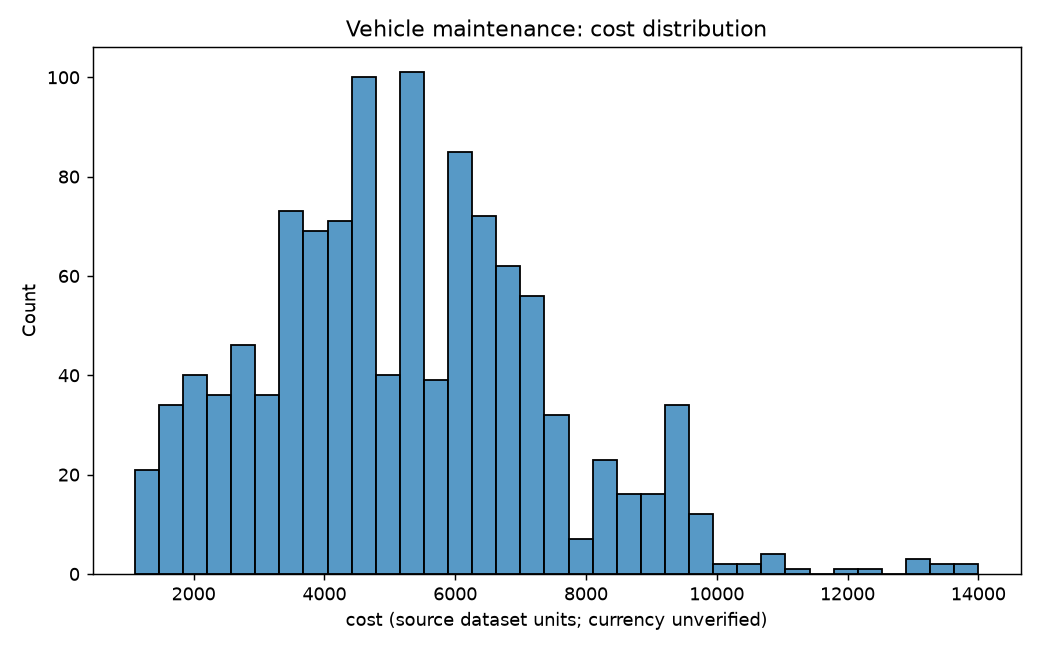

correlation_heatmap.png


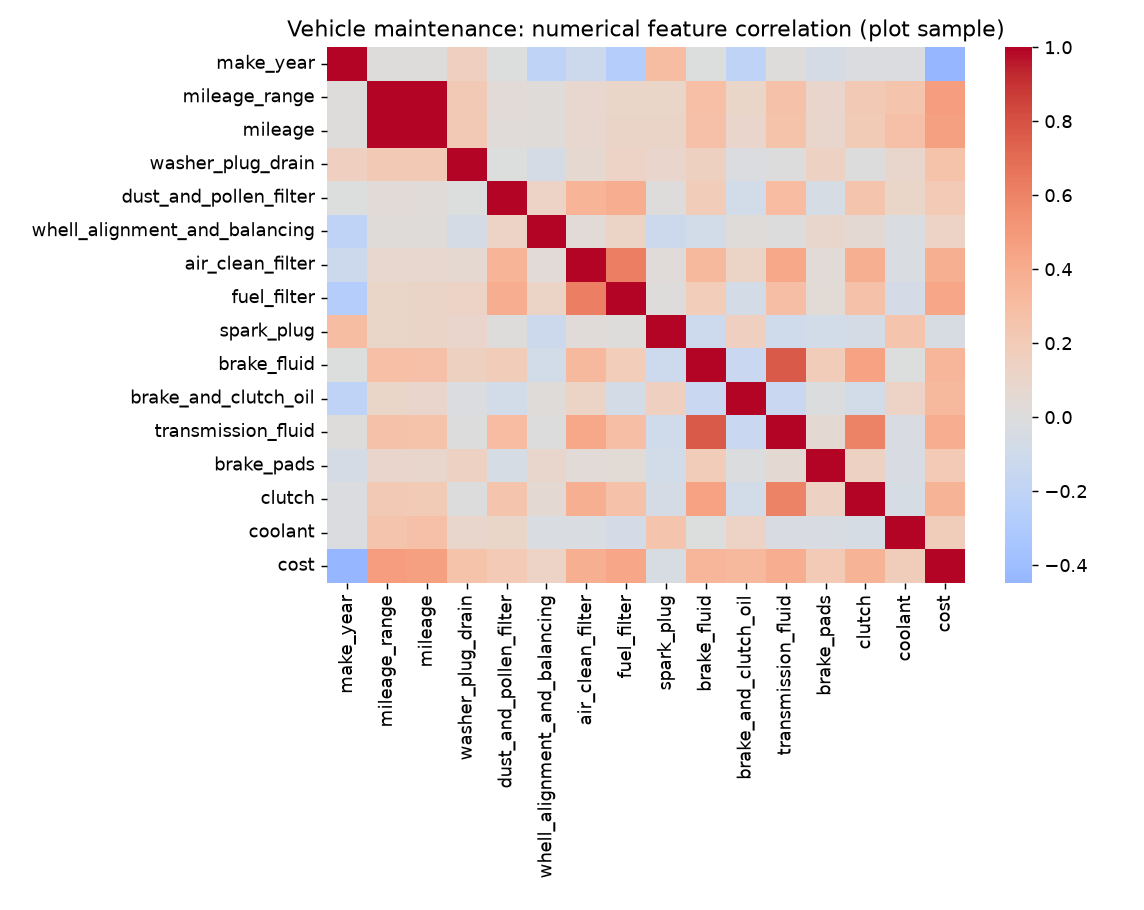

target_total_cost_histogram.png


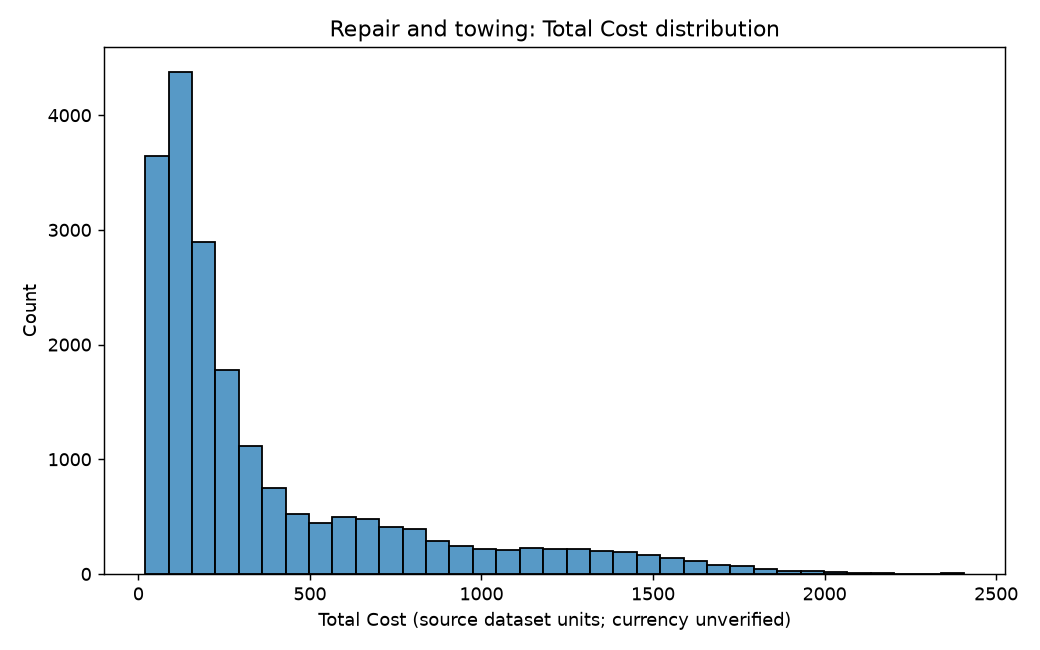

missing_values.png


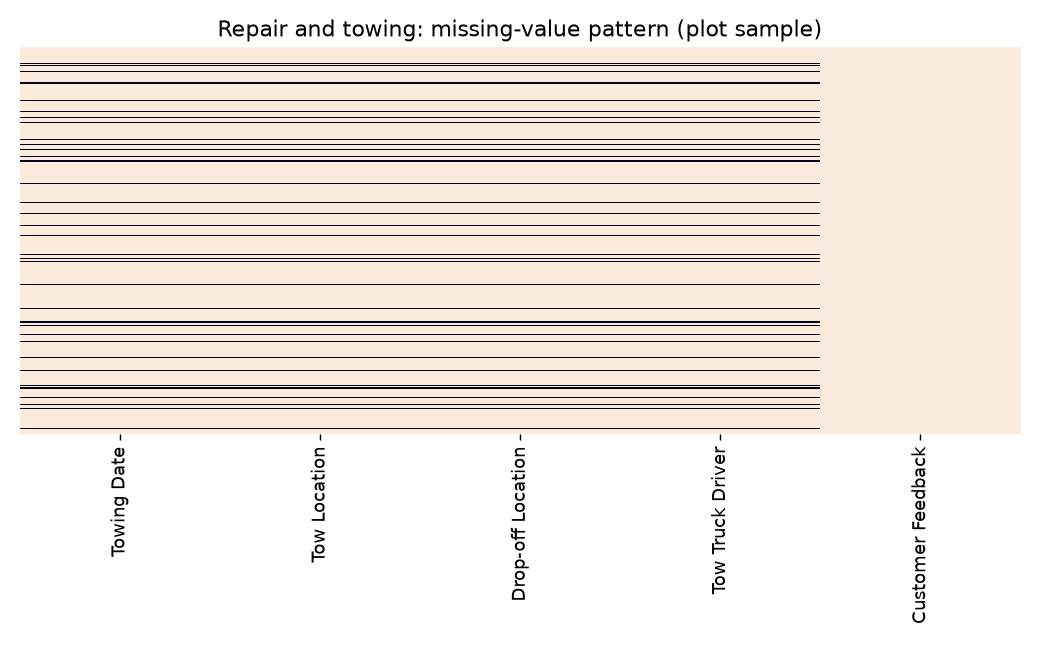

In [5]:
from IPython.display import Image, display
for image_path in [
    PLOT_DIR / 'vehicle_service' / 'target_cost_histogram.png',
    PLOT_DIR / 'vehicle_service' / 'correlation_heatmap.png',
    PLOT_DIR / 'repair_towing' / 'target_total_cost_histogram.png',
    PLOT_DIR / 'repair_towing' / 'missing_values.png',
]:
    if image_path.exists():
        print(image_path.name)
        display(Image(filename=str(image_path)))

# 7. Identify potential data-quality issues
An IQR flag is a prompt for investigation, not proof that a record is wrong. We also inspect category counts and exact duplicate rows; repeated repairs can be legitimate, so duplicates are reported rather than automatically removed.

In [6]:
print('Exact duplicate rows:', {'maintenance': int(service_data.duplicated().sum()),
                                'repair/towing': int(repair_data.duplicated().sum())})
print('Observed repair categories:', repair_data['Service Type'].value_counts(dropna=False).to_dict())
print('Observed vehicle types:', repair_data['Vehicle Type'].value_counts(dropna=False).to_dict())
print('Observed urgency values:', repair_data['Urgency Level'].value_counts(dropna=False).to_dict())
print('Service Status values:', repair_data['Service Status'].value_counts(dropna=False).to_dict())
print('Repair currency is not specified in the CSV; do not label its cost metrics INR.')

Exact duplicate rows: {'maintenance': 0, 'repair/towing': 0}
Observed repair categories: {'Oil Change': 286316, 'Engine Repair': 285929, 'Battery Replacement': 285923, 'Tire Replacement': 285837, 'Towing': 285738, 'Transmission Repair': 285692, 'Brake Service': 284565}
Observed vehicle types: {'Van': 334078, 'SUV': 333522, 'Bus': 333269, 'Truck': 333230, 'Car': 332956, 'Motorcycle': 332945}
Observed urgency values: {'Standard': 667288, 'Scheduled': 666450, 'Emergency': 666262}
Service Status values: {'s': 1999999, 'In Progress': 1}
Repair currency is not specified in the CSV; do not label its cost metrics INR.


# 8. Clean and preprocess the data
Invalid numeric feature values become missing and are imputed inside a Pipeline. Missing/invalid target rows are excluded because there is no correct target to learn. We do not fit imputers or encoders on the complete dataset.

In [7]:
for task_key, frame in [('service', service_data), ('repair', repair_data), ('category', repair_data)]:
    task = TASKS[task_key]
    features, numeric_features, categorical_features = select_features(frame, task)
    X_clean, y_clean = prepare_xy(frame, task, features, numeric_features)
    print(task['name'], 'clean X:', X_clean.shape, 'usable y:', y_clean.shape,
          'missing X cells:', int(X_clean.isna().sum().sum()))
    del X_clean, y_clean


vehicle_service_cost target: cost
Selected features: ['vehicle_type', 'brand', 'model', 'engine_type', 'make_year', 'region', 'mileage_range', 'mileage', 'oil_filter', 'engine_oil', 'washer_plug_drain', 'dust_and_pollen_filter', 'whell_alignment_and_balancing', 'air_clean_filter', 'fuel_filter', 'spark_plug', 'brake_fluid', 'brake_and_clutch_oil', 'transmission_fluid', 'brake_pads', 'clutch', 'coolant']
Excluded columns: ['slno']
Feature-selection rationale: Use vehicle, engine, mileage, region, and planned service-item inputs; exclude slno because it is a record identifier.
Rows excluded for invalid/missing target: 0
vehicle_service_cost clean X: (1139, 22) usable y: (1139,) missing X cells: 0

repair_cost target: Total Cost
Selected features: ['Vehicle Type', 'Make and Model', 'Service Type', 'Urgency Level', 'Customer Type', 'Insurance Claim Used', 'Is Warranty Valid', 'Mileage at Service']
Excluded columns: ['Service ID', 'Customer Name', 'Service Description', 'Repair Date', 'Tow

# 9. Separate features X and targets y
Each task has its own reviewed feature list. `cost`, `Total Cost`, `Service Type`, identifiers, post-service details, and estimated bill proxies are not accidentally fed into the wrong model.

In [8]:
service_features = TASKS['service']['features']
repair_cost_features = TASKS['repair']['features']
category_features = TASKS['category']['features']
X_service, y_service = prepare_xy(service_data, TASKS['service'], service_features,
                                   TASKS['service']['numeric'])
print('Maintenance X columns:', X_service.columns.tolist(), '| y:', TASKS['service']['target'])
print('Repair cost X columns:', repair_cost_features, '| y:', TASKS['repair']['target'])
print('Category X columns:', category_features, '| y:', TASKS['category']['target'])

Rows excluded for invalid/missing target: 0
Maintenance X columns: ['vehicle_type', 'brand', 'model', 'engine_type', 'make_year', 'region', 'mileage_range', 'mileage', 'oil_filter', 'engine_oil', 'washer_plug_drain', 'dust_and_pollen_filter', 'whell_alignment_and_balancing', 'air_clean_filter', 'fuel_filter', 'spark_plug', 'brake_fluid', 'brake_and_clutch_oil', 'transmission_fluid', 'brake_pads', 'clutch', 'coolant'] | y: cost
Repair cost X columns: ['Vehicle Type', 'Make and Model', 'Service Type', 'Urgency Level', 'Customer Type', 'Insurance Claim Used', 'Is Warranty Valid', 'Mileage at Service'] | y: Total Cost
Category X columns: ['Vehicle Type', 'Make and Model', 'Urgency Level', 'Customer Type', 'Insurance Claim Used', 'Is Warranty Valid', 'Mileage at Service'] | y: Service Type


# 10. Split data into training and testing sets
We reserve 20% for the final test and use a fixed seed. Classification is stratified when every class has enough examples. Cross-validation on the training partition acts as validation/model selection; the test partition is not used to select the model.

In [9]:
X_service_train, X_service_test, y_service_train, y_service_test, split_note = split_dataset(
    X_service, y_service, 'regression', RANDOM_SEED)
print('Maintenance split:', len(X_service_train), 'train rows;', len(X_service_test), 'test rows')
print('Numeric imputation and one-hot encoding are fitted within each model Pipeline, after this split.')

Original usable rows: 1,139; training: 911; testing: 228
Maintenance split: 911 train rows; 228 test rows
Numeric imputation and one-hot encoding are fitted within each model Pipeline, after this split.


# 11. Train maintenance-cost regressors
Both models use the same training split and preprocessing. The selected model is chosen by training-only cross-validation with negative MAE; negative scoring is used because scikit-learn maximizes scores.

In [10]:
def train_regression_task(frame, task_key):
    task = TASKS[task_key]
    features, numeric, categorical = select_features(frame, task)
    X, y = prepare_xy(frame, task, features, numeric)
    X_train, X_test, y_train, y_test, _ = split_dataset(X, y, task['kind'], RANDOM_SEED)
    candidates = build_candidates(task, numeric, categorical, RANDOM_SEED)
    cv, selected = cross_validate_candidates(candidates, X_train, y_train, task,
                                               folds=3, sample_size=25_000,
                                               random_seed=RANDOM_SEED)
    evaluation = fit_and_evaluate(candidates, selected, X_train, X_test,
                                  y_train, y_test, task, RANDOM_SEED)
    make_evaluation_plots(task, y_test, evaluation, PLOT_DIR / task['name'])
    return {'task': task, 'cv': cv, 'evaluation': evaluation,
            'pipeline': evaluation['selected_pipeline'], 'test_metrics': evaluation['comparison'],
            'example': X_test.iloc[0].to_dict(), 'test_rows': len(X_test)}

tutorial_results = {}
tutorial_results['vehicle_service_cost'] = train_regression_task(service_data, 'service')
tutorial_results['vehicle_service_cost']['test_metrics']


vehicle_service_cost target: cost
Selected features: ['vehicle_type', 'brand', 'model', 'engine_type', 'make_year', 'region', 'mileage_range', 'mileage', 'oil_filter', 'engine_oil', 'washer_plug_drain', 'dust_and_pollen_filter', 'whell_alignment_and_balancing', 'air_clean_filter', 'fuel_filter', 'spark_plug', 'brake_fluid', 'brake_and_clutch_oil', 'transmission_fluid', 'brake_pads', 'clutch', 'coolant']
Excluded columns: ['slno']
Feature-selection rationale: Use vehicle, engine, mileage, region, and planned service-item inputs; exclude slno because it is a record identifier.
Rows excluded for invalid/missing target: 0
Original usable rows: 1,139; training: 911; testing: 228
DecisionTree training CV: neg_mean_absolute_error mean=-378.84947, std=44.47477
RandomForest training CV: neg_mean_absolute_error mean=-344.17499, std=27.73769
Selected by training CV: RandomForest
Fitting DecisionTree on 911 training rows.
DecisionTree held-out metrics: {'mae': 401.47715643274864, 'mse': 711978.75

{'DecisionTree': {'mae': 401.47715643274864,
  'mse': 711978.7550248078,
  'rmse': 843.7883354401196,
  'r2': 0.8562026709339493},
 'RandomForest': {'mae': 370.5415119552974,
  'mse': 527763.0012667179,
  'rmse': 726.4729872932082,
  'r2': 0.8934084627856733}}

# 12. Train repair and towing cost regressors
The same workflow predicts `Total Cost` separately. The full dataset is used in the final train/test evaluation; only large-data cross-validation is capped at a deterministic training-only sample for practical runtime.

In [ ]:
tutorial_results['repair_cost'] = train_regression_task(repair_data, 'repair')
tutorial_results['repair_cost']['test_metrics']


repair_cost target: Total Cost
Selected features: ['Vehicle Type', 'Make and Model', 'Service Type', 'Urgency Level', 'Customer Type', 'Insurance Claim Used', 'Is Warranty Valid', 'Mileage at Service']
Excluded columns: ['Service ID', 'Customer Name', 'Service Description', 'Repair Date', 'Towing Date', 'Tow Location', 'Drop-off Location', 'Mechanic Name', 'Tow Truck Driver', 'Parts Used', 'Payment Method', 'Warranty Information', 'Service Status', 'Customer Feedback', 'Follow-up Needed', 'Service Duration Hours', 'Estimated Cost', 'Technician Rating', 'Tow Distance Miles']
Feature-selection rationale: Use vehicle, service type, urgency, customer/insurance/warranty context, and mileage available at request time. Exclude identifiers, Estimated Cost as a target proxy, and fields describing completed work.
Rows excluded for invalid/missing target: 0
Original usable rows: 2,000,000; training: 1,600,000; testing: 400,000
CV uses a deterministic 25,000-row sample from the training split; th

# 13. Train maintenance-category classifiers
The target is the seven `Service Type` values observed in the CSV; we do not discard categories that differ from a prewritten list. A majority-class DummyClassifier is evaluated as a baseline.

In [ ]:
def train_classification_task(frame):
    task = TASKS['category']
    features, numeric, categorical = select_features(frame, task)
    X, y = prepare_xy(frame, task, features, numeric)
    X_train, X_test, y_train, y_test, note = split_dataset(X, y, task['kind'], RANDOM_SEED)
    candidates = build_candidates(task, numeric, categorical, RANDOM_SEED)
    cv, selected = cross_validate_candidates(candidates, X_train, y_train, task,
                                               folds=3, sample_size=25_000,
                                               random_seed=RANDOM_SEED)
    evaluation = fit_and_evaluate(candidates, selected, X_train, X_test,
                                  y_train, y_test, task, RANDOM_SEED)
    make_evaluation_plots(task, y_test, evaluation, PLOT_DIR / task['name'])
    return {'task': task, 'cv': cv, 'evaluation': evaluation,
            'pipeline': evaluation['selected_pipeline'], 'test_metrics': evaluation['comparison'],
            'example': X_test.iloc[0].to_dict(), 'test_rows': len(X_test),
            'y_test': y_test, 'prediction': evaluation['selected_prediction'], 'split_note': note}

tutorial_results['maintenance_category'] = train_classification_task(repair_data)
print('Observed classes:', tutorial_results['maintenance_category']['pipeline'].named_steps['model'].classes_)
tutorial_results['maintenance_category']['test_metrics']

# 14. Evaluate regression models
MAE is average absolute error; RMSE penalizes large errors and remains in source units; R² compares against predicting a constant mean. No single metric, especially R², proves a model is practically accurate.

In [ ]:
regression_rows = []
for task_name in ['vehicle_service_cost', 'repair_cost']:
    for model_name, metrics in tutorial_results[task_name]['test_metrics'].items():
        regression_rows.append({'task': task_name, 'model': model_name, **metrics})
regression_comparison = pd.DataFrame(regression_rows)
display(regression_comparison)

# 15. Evaluate classifiers
Accuracy is the overall correct fraction; macro precision/recall/F1 weight classes equally; weighted F1 accounts for class support. The confusion matrix shows which classes are confused. Compare the models with the majority baseline.

In [ ]:
category_result = tutorial_results['maintenance_category']
print('Selected-model classification report:\n', category_result['evaluation']['classification_report'])
print('Majority baseline report:\n', category_result['evaluation']['baseline_report'])
print('Metrics including baseline:', category_result['test_metrics'])
labels = list(category_result['pipeline'].named_steps['model'].classes_)
cm = confusion_matrix(category_result['y_test'], category_result['prediction'], labels=labels)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted category'); plt.ylabel('Actual category'); plt.title('Held-out confusion matrix')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

# 16. Compare models using tables and plots
The test metrics are descriptive checks after cross-validation has already selected a model. They are not fed back into tuning or selection. Cost target scales remain separate.

In [ ]:
display(regression_comparison)
classification_table = pd.DataFrame(category_result['test_metrics']).T
display(classification_table)
classification_table[['accuracy', 'macro_f1', 'weighted_f1']].plot(kind='bar', ylim=(0, 1), figsize=(9, 5))
plt.title('Classifier and majority-baseline test comparison'); plt.ylabel('Score'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# 17. Save the selected fitted models
Each file stores a complete preprocessing-and-estimator Pipeline fitted on training data. This tutorial output directory is separate from both the preserved existing models and production output.

In [ ]:
TUTORIAL_MODEL_DIR = PROJECT_DIR / 'models' / 'tutorial'
TUTORIAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)
for task_name, result in tutorial_results.items():
    model_path = TUTORIAL_MODEL_DIR / f'{task_name}.joblib'
    joblib.dump(result['pipeline'], model_path)
    print('Saved:', model_path)
metrics = {name: result['test_metrics'] for name, result in tutorial_results.items()}
with (TUTORIAL_MODEL_DIR / 'metrics.json').open('w', encoding='utf-8') as output:
    json.dump(metrics, output, indent=2)

# 18. Demonstrate predictions on unseen examples
This record was held out from model fitting. The fitted Pipeline applies the same training-learned imputation and encoding. For a real new maintenance request, provide exactly the feature names shown here.

In [ ]:
for task_name, result in tutorial_results.items():
    pipeline = joblib.load(TUTORIAL_MODEL_DIR / f'{task_name}.joblib')
    example = pd.DataFrame([result['example']], columns=pipeline.feature_names_in_)
    prediction = pipeline.predict(example)[0]
    print(f'{task_name} held-out example prediction:', prediction,
          '(source cost units)' if result['task']['kind'] == 'regression' else '(service category)')

service_example = pd.DataFrame([tutorial_results['vehicle_service_cost']['example']],
                               columns=tutorial_results['vehicle_service_cost']['pipeline'].feature_names_in_)
print('Service feature names:', service_example.columns.tolist())

# 19. Summarize results and limitations
The production trainer writes the detailed metrics, metadata, and plots to `reports/production_v2` and `plots/production_v2`. Review the actual metric tables above before presenting results. Neither dataset identifies currency; the repair source has a highly repetitive status field; random splitting does not test generalization to unseen vehicles/customers; and tree feature importance is not causation.

In [ ]:
for task_name, result in tutorial_results.items():
    selected = result['evaluation']['selected_name']
    print(f'{task_name}: selected by training-only CV = {selected}')
    print('  held-out test metrics =', result['test_metrics'][selected])
print('Do not compare maintenance and repair cost errors as if they shared a currency or scale.')